<font size = 3 color="gray">Máster Universitario en inteligencia artificial (MUIA)</font> 

# Red neuronal sencilla con TensorFlow (versión compacta)

La misma red que `bp_hardwired_ReLU` (2 entradas → 4 neuronas ReLU → 1 salida sigmoide, SGD con lotes de 100, η = 1, 100 épocas), con los mismos datos y los mismos pesos iniciales, escrita con la API de alto nivel **Keras**:

* **GPU:** TensorFlow coloca automáticamente las operaciones en la GPU si la detecta; no hace falta mover a mano el modelo ni los datos, como el `.to(device)` de PyTorch.
* **`Sequential` + `Dense`:** la red se declara en una línea. Keras guarda los pesos de cada capa como matriz `(n_in, n_out)`, la traspuesta de `w[l]` en el notebook original.
* **`BinaryCrossentropy(from_logits=True)`:** integra la sigmoide en la pérdida, igual que `BCEWithLogitsLoss` en PyTorch. La red devuelve el *logit* $z$; la clase es 1 si $z > 0$.
* **`compile` + `fit`:** sustituyen al bucle de entrenamiento. `fit` baraja los datos en cada época, hace los lotes, calcula los gradientes y actualiza los pesos. Tampoco hace falta un equivalente a `torch.no_grad()`: `evaluate` y `predict` no calculan gradientes.

In [1]:
import numpy as np, tensorflow as tf, matplotlib.pyplot as plt
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponible:" if gpus else "No hay GPU: se usará la CPU", *[g.name for g in gpus])
np.random.seed(2026); tf.random.set_seed(2026)

def crea_datos(n):   # entradas (x, y) y etiqueta (frontera de tres regiones)
    x, y = np.random.rand(2, n)
    return np.c_[x, y].astype("float32"), ((x**2 + y**2 < 0.7**2) | (x > 0.9)).astype("float32")[:, None]

(X, y), (Xt, yt) = crea_datos(8000), crea_datos(2000)
model = tf.keras.Sequential([tf.keras.Input((2,)), tf.keras.layers.Dense(4, activation="relu"), tf.keras.layers.Dense(1)])
# He (capa ReLU) y Xavier (capa sigmoide), con los mismos valores que el original (traspuestos: Keras usa (n_in, n_out))
model.set_weights([np.random.randn(4, 2).T * np.sqrt(2 / 2), np.zeros(4), np.random.randn(1, 4).T * np.sqrt(1 / 4), np.zeros(1)])
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=1.0), loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.0)])   # umbral 0 sobre el logit = 0.5 sobre la sigmoide
print(f"Tasa de acierto antes de entrenar: {model.evaluate(X, y, verbose=0)[1]:.4f}")

No hay GPU: se usará la CPU


Tasa de acierto antes de entrenar: 0.5820


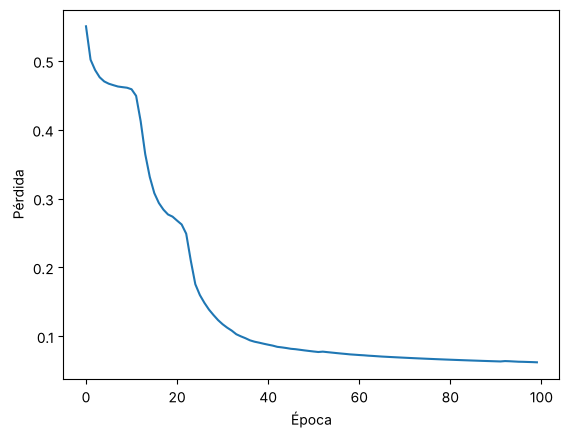

In [2]:
hist = model.fit(X, y, batch_size=100, epochs=100, shuffle=True, verbose=0)
plt.plot(hist.history["loss"]); plt.xlabel("Época"); plt.ylabel("Pérdida"); plt.show()

Tasa de acierto en test: 0.9810


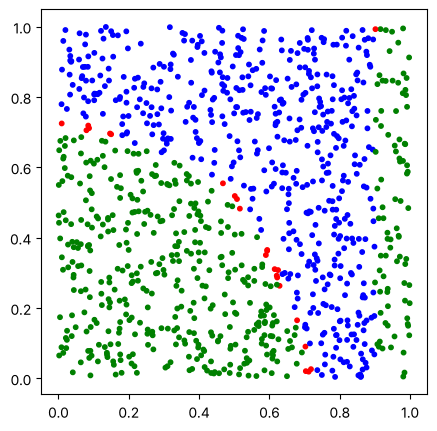

In [3]:
print(f"Tasa de acierto en test: {model.evaluate(Xt, yt, verbose=0)[1]:.4f}")
pred = (model.predict(Xt[:1000], verbose=0) > 0).ravel()
plt.figure(figsize=(5, 5)); plt.gca().set_aspect("equal")
plt.scatter(Xt[:1000, 0], Xt[:1000, 1], s=10, c=np.where(pred != yt[:1000, 0], "red", np.where(pred, "green", "blue"))); plt.show()

---

<font size="1" color="grey">
    (c) 2026 Javier García Algarra. <a href='https://www.u-tad.com'>www.u-tad.com</a> <br>
Licensed under a Creative Commons Reconocimiento 4.0 Internacional License
</font>